# Bài 1 — K-Nearest Neighbors tự cài đặt

**Câu hỏi thực nghiệm:** Scaling có làm thay đổi chất lượng KNN? `k`, khoảng cách và weighting nào phù hợp nhất? Cách vote theo láng giềng giải thích được một dự đoán cụ thể ra sao?

Dữ liệu Rice Cammeo/Osmancik gồm 7 đặc trưng hình thái số và 2 lớp. Bản ARFF đi kèm lấy từ nguồn dataset của Murat Koklu; nghiên cứu gốc được trích trong file dữ liệu. Bài dùng train/test phân tầng 80/20 với `SEED=42`, sau đó 5-fold CV trên train. Macro-F1 là metric chính để cân bằng đóng góp hai lớp. Test chỉ dùng sau khi đã chọn cấu hình.

**Lưu ý khi đọc:** Các con số trong phần nhận xét thuộc lần chạy đã lưu với Rice ARFF và `SEED=42`. Nếu thay dữ liệu, seed hoặc phiên bản thư viện, cần đọc lại output trước khi dùng các kết luận định lượng.

## Thư viện và cấu hình thực nghiệm

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import arff
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, log_loss

**Cấu hình.** Seed 42 cố định phép chia dữ liệu và các fold. Notebook ưu tiên ARFF cạnh notebook, sau đó tìm từ thư mục gốc repository; nếu thiếu file, thông báo lỗi rõ đường dẫn cần có.

In [2]:
SEED = 42
DATA_PATH = Path("data/Rice_Cammeo_Osmancik.arff")
if not DATA_PATH.exists():
    DATA_PATH = Path("knn-prob-model/data/Rice_Cammeo_Osmancik.arff")
if not DATA_PATH.exists():
    raise FileNotFoundError("Rice ARFF not found beside this notebook or under knn-prob-model/data")

## 1. Đọc và kiểm tra dữ liệu

Xem mẫu dữ liệu, kiểu cột, khoảng biến thiên, giá trị thiếu, hàng trùng và số mẫu từng lớp trước khi huấn luyện. Các cột hình thái là số thực; nhãn `Class` được tách khỏi đặc trưng.

In [3]:
raw, metadata = arff.loadarff(DATA_PATH)

data = pd.DataFrame(raw)

# ARFF nominal labels arrive as bytes; decode them before splitting.
for column in data.select_dtypes(include="object").columns:
    data[column] = data[column].str.decode("utf-8")

target_name = "Class"
X = data.drop(columns=target_name).to_numpy(dtype=float)
y = data[target_name].to_numpy()
feature_names = data.drop(columns=target_name).columns.tolist()
class_names, class_counts = np.unique(y, return_counts=True)

print(f"Dataset: Rice Cammeo/Osmancik | shape={data.shape} | seed={SEED}")
display(data.head())
display(data.dtypes.to_frame("dtype"))
display(data.describe().loc[["min", "max", "std"]].T)
display(pd.DataFrame({"count": class_counts}, index=class_names).rename_axis("class"))
print("Missing:", int(data.isna().sum().sum()), "| duplicates:", int(data.duplicated().sum()))
assert np.isfinite(X).all() and not pd.isna(y).any()

Dataset: Rice Cammeo/Osmancik | shape=(3810, 8) | seed=42


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231.0,525.578979,229.749878,85.093788,0.928882,15617.0,0.572896,Cammeo
1,14656.0,494.311005,206.020065,91.730972,0.895405,15072.0,0.615436,Cammeo
2,14634.0,501.122009,214.106781,87.768288,0.912118,14954.0,0.693259,Cammeo
3,13176.0,458.342987,193.337387,87.448395,0.891861,13368.0,0.640669,Cammeo
4,14688.0,507.166992,211.743378,89.312454,0.906691,15262.0,0.646024,Cammeo


,dtype
Area,float64
Perimeter,float64
Major_Axis_Length,float64
Minor_Axis_Length,float64
Eccentricity,float64
Convex_Area,float64
Extent,float64
Class,str


,min,max,std
Area,7551.000000,18913.000000,1732.367706
Perimeter,359.100006,548.445984,35.597081
Major_Axis_Length,145.264465,239.010498,17.448679
Minor_Axis_Length,59.532406,107.542450,5.729817
Eccentricity,0.777233,0.948007,0.020818
Convex_Area,7723.000000,19099.000000,1776.972042
Extent,0.497413,0.861050,0.077239


,count
class,
Cammeo,1630
Osmancik,2180


Missing: 0 | duplicates: 0


**Nhận xét dữ liệu.** Rice có 3.810 mẫu, 7 đặc trưng số, 1.630 Cammeo và 2.180 Osmancik. Không có giá trị thiếu hoặc hàng trùng trong ARFF đang dùng. Các cột diện tích có trị số hàng nghìn, còn `Extent` là tỉ lệ; khoảng cách trên dữ liệu gốc vì vậy dễ bị các cột có độ lớn lớn chi phối. Tỉ lệ lớp 42,8%/57,2% là lý do dùng macro-F1 để cho hai lớp trọng số ngang nhau.

### Phân hoạch và giữ test độc lập

Chia phân tầng 80/20 một lần: 3.048 mẫu dùng cho 5-fold CV, 762 mẫu giữ đến cuối. Mỗi fold fit scaler trên chính training fold của nó. Hai notebook dùng cùng split để có thể đối chiếu, nhưng mỗi bài chọn cấu hình riêng.

In [4]:
# Reserve a stratified test set before any model selection.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Train={len(y_train)}, test={len(y_test)}; test is held out until final evaluation.")

Train=3048, test=762; test is held out until final evaluation.


**Kiểm tra phân hoạch.** Seed, phân tầng và số lượng mẫu được in ra ngay trên. Tập test chưa tham gia bất kỳ phép chọn tham số hay scaler nào ở các phần tiếp theo.

## 2. KNN từ khoảng cách đến phiếu bầu

Với hai vectơ $x,z$, notebook dùng $d_2(x,z)=\sqrt{\sum_j(x_j-z_j)^2}$ và $d_1(x,z)=\sum_j|x_j-z_j|$. Dự đoán lấy $k$ điểm training gần nhất; uniform cho mỗi điểm một phiếu, còn distance weighting dùng $1/d$ khi $d>0$. Nếu có điểm trùng hẳn, chỉ những điểm $d=0$ bỏ phiếu để tránh chia cho 0. Khi hòa phiếu, lớp có thứ tự từ điển trước thắng.

`k` nhỏ có thể nhạy với nhiễu; `k` lớn làm biên quyết định mượt hơn nhưng có thể bỏ qua cấu trúc cục bộ. Vì khoảng cách phụ thuộc đơn vị đo, scaling là một lựa chọn cần đánh giá trong CV.

Mỗi phương thức được định nghĩa ở một cell để dễ đọc. Python yêu cầu thân class liền mạch, nên các hàm nhận `self` dưới đây được gắn vào class ở cell cuối.

### `fit`

Kiểm tra đầu vào và lưu tập train cùng thứ tự lớp; KNN dùng các mẫu này khi dự đoán.

In [5]:
def _knn_fit(self, X, y):
    # Store the training examples because KNN has no parameter fitting step.
    self.X_ = np.asarray(X, dtype=float)
    self.y_ = np.asarray(y)
    self.classes_ = np.unique(self.y_)

    if self.X_.ndim != 2 or len(self.X_) != len(self.y_) or not len(self.y_):
        raise ValueError("X must be a non-empty 2D array aligned with y")
    if not np.isfinite(self.X_).all():
        raise ValueError("KNN features must be finite")
    if not 1 <= self.n_neighbors <= len(self.y_):
        raise ValueError("n_neighbors must be in [1, n_samples]")
    if self.metric not in {"euclidean", "manhattan"}:
        raise ValueError("Unsupported metric")
    if self.weights not in {"uniform", "distance"}:
        raise ValueError("Unsupported weighting")
    return self

### `_distances`

Tính khoảng cách Euclidean hoặc Manhattan từ mẫu cần dự đoán tới từng mẫu train; xử lý theo khối để kiểm soát bộ nhớ.

In [6]:
def _knn_distances(self, X):
    X = np.asarray(X, dtype=float)

    if self.metric == "euclidean":
        # Expand squared distance to avoid a large 3D temporary array.
        x_norm = np.einsum("ij,ij->i", X, X)[:, None]
        train_norm = np.einsum("ij,ij->i", self.X_, self.X_)[None, :]
        return np.sqrt(np.maximum(x_norm + train_norm - 2.0 * X @ self.X_.T, 0.0))

    # Process Manhattan distances in blocks to limit memory use.
    result = np.empty((len(X), len(self.X_)), dtype=float)
    for start in range(0, len(X), 128):
        block = X[start:start + 128]
        result[start:start + len(block)] = np.abs(block[:, None, :] - self.X_[None, :, :]).sum(axis=2)
    return result

### `kneighbors`

Sắp xếp khoảng cách ổn định và lấy đúng `k` láng giềng gần nhất cùng chỉ số của chúng.

In [7]:
def _knn_kneighbors(self, X):
    distances = self._distances(X)
    # Lexicographic ordering makes equal-distance neighbor selection deterministic.
    order = np.argsort(distances, axis=1, kind="stable")[:, : self.n_neighbors]
    return np.take_along_axis(distances, order, axis=1), order

### `predict_proba`

Chuyển nhãn láng giềng thành phiếu theo weighting, xử lý khoảng cách bằng 0 và chuẩn hóa tổng phiếu theo lớp.

In [8]:
def _knn_predict_proba(self, X):
    distances, indices = self.kneighbors(X)
    probabilities = np.zeros((len(indices), len(self.classes_)), dtype=float)

    for row, (neighbor_distances, neighbor_indices) in enumerate(zip(distances, indices)):
        labels = self.y_[neighbor_indices]
        if self.weights == "uniform":
            weights = np.ones(len(labels), dtype=float)
        elif np.any(neighbor_distances == 0):
            # Exact matches dominate; split their vote uniformly to avoid infinities.
            weights = (neighbor_distances == 0).astype(float)
        else:
            weights = 1.0 / neighbor_distances

        # Normalize class votes so each row sums to one.
        for class_index, label in enumerate(self.classes_):
            probabilities[row, class_index] = weights[labels == label].sum()
        probabilities[row] /= probabilities[row].sum()
    return probabilities

### `predict`

Chọn lớp có tổng phiếu lớn nhất; nếu hòa, ưu tiên lớp đứng trước trong thứ tự đã lưu.

In [9]:
def _knn_predict(self, X):
    # np.argmax resolves voting ties by the sorted class order.
    return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

### Ghép các phương thức vào `NumpyKNN`

`__init__` lưu cấu hình; các phương thức ở trên được gắn vào class để dùng với `Pipeline` và cross-validation.

In [10]:
class NumpyKNN(ClassifierMixin, BaseEstimator):
    """KNN classifier using NumPy distances and voting only."""

    def __init__(self, n_neighbors=5, metric="euclidean", weights="uniform"):
        self.n_neighbors = n_neighbors
        self.metric = metric
        self.weights = weights

    fit = _knn_fit
    _distances = _knn_distances
    kneighbors = _knn_kneighbors
    predict_proba = _knn_predict_proba
    predict = _knn_predict

### Kiểm tra hành vi của cài đặt

Các ví dụ nhỏ kiểm tra điểm trùng, thứ tự láng giềng, hòa phiếu và `k` không hợp lệ. scikit-learn chỉ xuất hiện ở bước đối chiếu sau khi lớp NumPy đã được xây dựng.

In [11]:
toy = NumpyKNN(n_neighbors=3, metric="euclidean", weights="distance").fit(
    np.array([[0.0], [0.0], [2.0], [3.0]]), np.array(["A", "A", "B", "B"])
)

# Exact matches must produce finite probabilities and stable neighbor order.
toy_prob = toy.predict_proba([[0.0]])
assert toy.predict([[0.0]])[0] == "A" and np.isfinite(toy_prob).all()
assert np.allclose(toy_prob.sum(axis=1), 1.0)
assert np.array_equal(toy.kneighbors([[0.0]])[1][0], [0, 1, 2])
tie_model = NumpyKNN(n_neighbors=2, metric="euclidean", weights="uniform").fit(
    np.array([[-1.0], [1.0]]), np.array(["A", "B"]))
assert tie_model.predict([[0.0]])[0] == "A"  # deterministic class-order tie break

# An invalid number of neighbors must be rejected.
try:
    NumpyKNN(n_neighbors=0).fit([[0.0]], ["A"])
except ValueError:
    pass
else:
    raise AssertionError("Invalid k was not rejected")

### Đối chiếu với scikit-learn

Hai mô hình cùng học trên phần train của fold đầu tiên và dự đoán trên phần validation của fold đó.

In [12]:
from sklearn.neighbors import KNeighborsClassifier

# Compare both implementations on the first validation fold inside train.
reference_train_idx, reference_val_idx = next(cv.split(X_train, y_train))
reference = KNeighborsClassifier(n_neighbors=7, metric="euclidean", weights="uniform")
reference.fit(X_train[reference_train_idx], y_train[reference_train_idx])
ours = NumpyKNN(n_neighbors=7, metric="euclidean", weights="uniform").fit(
    X_train[reference_train_idx], y_train[reference_train_idx])
agreement = np.mean(
    ours.predict(X_train[reference_val_idx]) == reference.predict(X_train[reference_val_idx]))
print(f"Prediction agreement with scikit-learn: {agreement:.4f}")
assert agreement == 1.0

Prediction agreement with scikit-learn: 1.0000


**Kết quả đối chiếu.** Với `k=7`, Euclidean và uniform trên fold validation đầu tiên của training split, hai bộ phân loại cho cùng nhãn ở toàn bộ 610 mẫu (agreement `1.0000`). Ca điểm trùng trả xác suất hữu hạn; ca hòa phiếu chọn lớp A theo quy tắc đã định. Bước này kiểm tra cài đặt mà không đọc test trước lúc chọn cấu hình.

## 3. Thiết kế cross-validation

Mỗi fold tạo scaler từ training fold, tính ma trận khoảng cách bằng NumPy và dùng chung thứ tự láng giềng cho các giá trị `k`/weighting. Điều này giảm tính toán lặp. Đường train dùng leave-one-out trong training fold: tự loại chính mẫu đang xét khỏi danh sách láng giềng, tránh điểm tự khớp làm điểm train tăng giả. Macro-F1 validation trung bình chọn cấu hình; độ lệch chuẩn, `k` và cấu hình đơn giản hơn giải hòa.

### Hàm tổng hợp phiếu cho nhiều cấu hình

In [13]:
from sklearn.metrics import f1_score

def vote_from_neighbors(distances, indices, reference_y, k, weights, classes):
    """Reuse a distance ranking when comparing several k and voting rules."""
    selected_distances = np.take_along_axis(distances, indices[:, :k], axis=1)
    selected_indices = indices[:, :k]
    predicted = []

    for row_distances, row_indices in zip(selected_distances, selected_indices):
        labels = reference_y[row_indices]
        vote_weights = np.ones(k, dtype=float)
        if weights == "distance":
            if np.any(row_distances == 0):
                vote_weights = (row_distances == 0).astype(float)
            else:
                vote_weights = 1.0 / row_distances
        scores = np.array([vote_weights[labels == label].sum() for label in classes])
        predicted.append(classes[np.argmax(scores)])
    return np.asarray(predicted)

### Quét scaling, khoảng cách, weighting và số láng giềng

In [14]:
rows = []
max_k = 31

# Each validation fold is kept out of the corresponding scaler fit.
for train_index, validation_index in cv.split(X_train, y_train):
    fold_X, fold_y = X_train[train_index], y_train[train_index]
    validation_X, validation_y = X_train[validation_index], y_train[validation_index]
    for scale in [False, True]:
        scaler = StandardScaler().fit(fold_X) if scale else None
        transformed_train = scaler.transform(fold_X) if scaler else fold_X
        transformed_validation = scaler.transform(validation_X) if scaler else validation_X

        for metric in ["euclidean", "manhattan"]:
            # Compute each distance matrix once and reuse it across the grid.
            distance_model = NumpyKNN(n_neighbors=max_k, metric=metric).fit(transformed_train, fold_y)
            validation_distances = distance_model._distances(transformed_validation)
            validation_order = np.argsort(validation_distances, axis=1, kind="stable")[:, :max_k]
            train_distances = distance_model._distances(transformed_train)
            np.fill_diagonal(train_distances, np.inf)
            train_order = np.argsort(train_distances, axis=1, kind="stable")[:, :max_k]

            for weights in ["uniform", "distance"]:
                for k in [1, 5, 11, 21, 31]:
                    validation_pred = vote_from_neighbors(
                        validation_distances, validation_order, fold_y, k, weights, class_names)
                    train_pred = vote_from_neighbors(
                        train_distances, train_order, fold_y, k, weights, class_names)
                    rows.append({
                        "fold": int(len(rows)), "scale": scale, "metric": metric,
                        "weights": weights, "k": k,
                        "cv_macro_f1": f1_score(validation_y, validation_pred, average="macro"),
                        "train_macro_f1": f1_score(fold_y, train_pred, average="macro"),
                        "cv_accuracy": accuracy_score(validation_y, validation_pred),
                    })
cv_fold_results = pd.DataFrame(rows)

### Tổng hợp kết quả và chốt cấu hình theo CV

In [15]:
# Aggregate across folds before applying the documented selection rule.
cv_results = cv_fold_results.groupby(
    ["scale", "metric", "weights", "k"], as_index=False
).agg(cv_macro_f1=("cv_macro_f1", "mean"), cv_macro_f1_std=("cv_macro_f1", "std"),
      train_macro_f1=("train_macro_f1", "mean"), cv_accuracy=("cv_accuracy", "mean"))
cv_results = cv_results.sort_values(
    ["cv_macro_f1", "cv_macro_f1_std", "k", "weights", "metric", "scale"],
    ascending=[False, True, True, True, True, True], kind="stable"
).reset_index(drop=True)
display(cv_results.head(12).round(4))
best = cv_results.iloc[0]
best_config = {"scale": bool(best.scale), "metric": best.metric,
               "weights": best.weights, "k": int(best.k)}
print("Selected from CV only:", best_config)

,scale,metric,weights,k,cv_macro_f1,cv_macro_f1_std,train_macro_f1,cv_accuracy
0,True,euclidean,uniform,31,0.9286,0.0113,0.9280,0.9301
1,True,manhattan,uniform,21,0.9286,0.0098,0.9265,0.9301
2,True,euclidean,uniform,21,0.9280,0.0103,0.9274,0.9295
3,True,manhattan,uniform,31,0.9277,0.0117,0.9258,0.9291
4,True,manhattan,distance,21,0.9276,0.0102,0.9267,0.9291
5,True,euclidean,distance,21,0.9270,0.0105,0.9279,0.9285
6,True,manhattan,distance,31,0.9263,0.0107,0.9268,0.9278
7,True,euclidean,distance,31,0.9256,0.0117,0.9281,0.9272
8,True,euclidean,distance,11,0.9256,0.0099,0.9250,0.9272
9,True,euclidean,uniform,5,0.9250,0.0074,0.9184,0.9265


Selected from CV only: {'scale': True, 'metric': 'euclidean', 'weights': 'uniform', 'k': 31}


**Nhận xét bảng CV.** Cấu hình đứng đầu là có scaling, Euclidean, uniform và `k=31`, với macro-F1 validation `0.9286` (độ lệch chuẩn `0.0113`). Các hàng đầu bảng đều bật scaling; điều này phù hợp với sự chênh lệch thang đo quan sát ở bảng dữ liệu. Điểm train leave-one-out của cấu hình chọn là `0.9280`, gần điểm validation, nên bảng này chưa cho thấy khoảng cách train/validation lớn.

### Đồ thị theo `k`

Hai ô hình cố định weighting của cấu hình thắng, rồi so sánh Euclidean/Manhattan khi bật và tắt scaling. Đường nét đứt là train leave-one-out; đường liền là validation. Nhìn đồng thời hai đường để phát hiện vùng `k` quá nhỏ hoặc quá lớn.

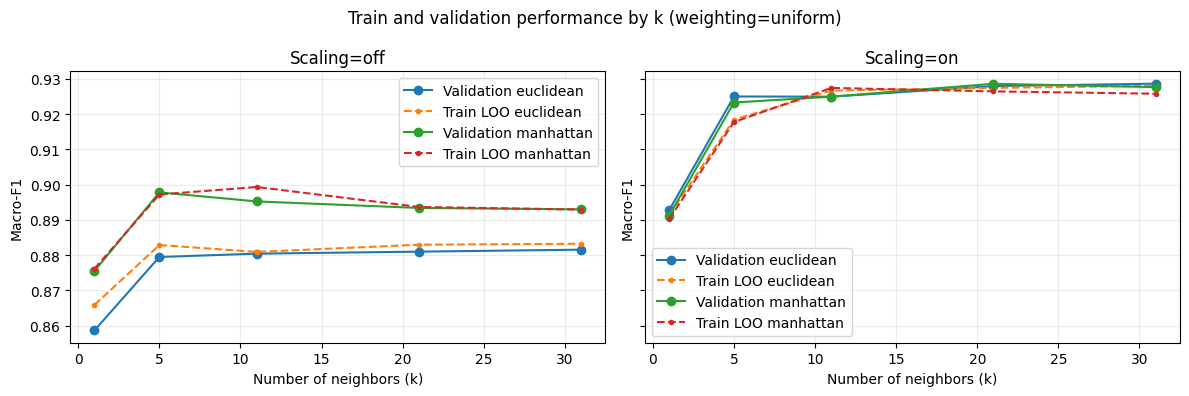

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

# Hold the winning weighting fixed while comparing scaling and distance.
for axis, scale in zip(axes, [False, True]):
    subset = cv_results[cv_results.scale == scale]
    for metric in ["euclidean", "manhattan"]:
        curve = subset[(subset.metric == metric) & (subset.weights == best.weights)].sort_values("k")
        axis.plot(curve.k, curve.cv_macro_f1, marker="o", label=f"Validation {metric}")
        axis.plot(curve.k, curve.train_macro_f1, marker=".", linestyle="--", label=f"Train LOO {metric}")
    axis.set(title=f"Scaling={'on' if scale else 'off'}", xlabel="Number of neighbors (k)", ylabel="Macro-F1")
    axis.grid(alpha=0.25)
    axis.legend()

plt.suptitle(f"Train and validation performance by k (weighting={best.weights})")
plt.tight_layout()
plt.show()

**Nhận xét hình.** Khi tắt scaling, validation macro-F1 của Euclidean chỉ quanh `0.88` và Manhattan quanh `0.89` ở các `k≥5`; sau scaling, hai đường tăng lên khoảng `0.925–0.929`. Dữ liệu có các cột diện tích hàng nghìn và `Extent` chỉ là tỉ lệ, nên chuẩn hóa làm các chiều đóng góp cân đối hơn vào khoảng cách. Từ `k=5` đến `31`, hai đường sau scaling khá phẳng; `k=31` chỉ tốt nhất trong grid đã thử. Đường train leave-one-out có thể thấp hơn validation ở vài điểm vì mỗi mẫu train không tự làm láng giềng cho chính nó.

## 4. Khóa cấu hình trước đánh giá cuối

Từ đây giữ cố định `best_config` chọn ở bảng CV. Fit scaler và KNN trên toàn bộ 3.048 mẫu training; không thay đổi cấu hình sau khi xem test.

In [17]:
final_steps = []
if best_config["scale"]:
    final_steps.append(("scale", StandardScaler()))

final_steps.append(("knn", NumpyKNN(n_neighbors=best_config["k"],
                                    metric=best_config["metric"],
                                    weights=best_config["weights"])))
final_model = Pipeline(final_steps).fit(X_train, y_train)

# Evaluate only after the configuration has been selected by CV.

### Đánh giá một lần trên test

In [18]:
test_pred = final_model.predict(X_test)
test_prob = final_model.predict_proba(X_test)
test_metrics = pd.Series({
    "accuracy": accuracy_score(y_test, test_pred),
    "macro_f1": f1_score(y_test, test_pred, average="macro"),
}, name="test")
display(test_metrics.to_frame().round(4))
display(pd.DataFrame(confusion_matrix(y_test, test_pred, labels=final_model.classes_),
                     index=final_model.classes_, columns=final_model.classes_).rename_axis("Actual").assign())

,test
accuracy,0.9108
macro_f1,0.9084


,Cammeo,Osmancik
Actual,,
Cammeo,286,40
Osmancik,28,408


**Nhận xét test.** Accuracy `0.9108`, macro-F1 `0.9084`, thấp hơn CV macro-F1 khoảng `0.0202`. Trong confusion matrix, 40 Cammeo bị dự đoán Osmancik và 28 Osmancik bị dự đoán Cammeo. Chênh lệch CV/test trên một split chưa đủ để kết luận quá khớp; cần lặp phép chia hoặc kiểm tra dữ liệu khác để đánh giá độ ổn định.

## 5. Giải thích một mẫu held-out

Mẫu đầu của test chỉ dùng để đọc cơ chế dự đoán sau khi mô hình đã chốt. Bảng in thứ tự láng giềng, khoảng cách sau scaling và nhãn từng điểm.

In [19]:
query_index = 0
query = X_test[query_index:query_index + 1]
knn_model = final_model.named_steps["knn"]

# Apply the same transformation used to fit the selected model.
query_transformed = final_model.named_steps["scale"].transform(query) if best_config["scale"] else query
train_transformed = final_model.named_steps["scale"].transform(X_train) if best_config["scale"] else X_train
distances, neighbor_indices = knn_model.kneighbors(query_transformed)

# Display which training examples contributed votes for this prediction.
neighbor_table = pd.DataFrame({
    "neighbor_rank": np.arange(1, best_config["k"] + 1),
    "train_index": neighbor_indices[0],
    "distance": distances[0],
    "class": y_train[neighbor_indices[0]],
})
display(neighbor_table)
print("Actual:", y_test[query_index], "| predicted:", test_pred[query_index],
      "| class probabilities:", dict(zip(knn_model.classes_, test_prob[query_index].round(4))))

,neighbor_rank,train_index,distance,class
0,1,3027,0.137318,Cammeo
1,2,2380,0.175971,Cammeo
2,3,843,0.211668,Cammeo
3,4,1846,0.227242,Cammeo
4,5,1555,0.252833,Cammeo
5,6,1151,0.295236,Cammeo
6,7,1215,0.297893,Cammeo
7,8,2283,0.322873,Cammeo
8,9,2544,0.331521,Cammeo
9,10,2128,0.335884,Cammeo


Actual: Cammeo | predicted: Cammeo | class probabilities: {'Cammeo': np.float64(0.9677), 'Osmancik': np.float64(0.0323)}


**Nhận xét dự đoán.** Mẫu thật là Cammeo và được dự đoán Cammeo. Trong 31 láng giềng có 30 Cammeo và 1 Osmancik; uniform voting cho Cammeo xác suất phiếu `30/31 = 0.9677`. Giá trị này là tỉ lệ phiếu của KNN, chưa được kiểm định là xác suất hiệu chỉnh.

## 6. Giới hạn và kết luận

KNN trên Rice phụ thuộc rõ vào đơn vị đặc trưng, nên so sánh scaling là cần thiết. Bộ phân loại lưu toàn bộ train và tính khoảng cách khi suy luận, khiến chi phí tăng theo số mẫu. Ở thí nghiệm này, cấu hình chọn bằng CV đạt test macro-F1 `0.9084`; kết luận chỉ áp dụng cho split và grid đã ghi.